# Precios de Steam en Argentina
Análisis de los datos de `data/`. Cada celda responde una pregunta del README.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

precios = pd.read_csv("../data/precios_steam_2026-11-13.csv")
# Argentina vs EE. UU., sobre el precio de lista (sin descuento)
precios["ar_sobre_us"] = precios["ar_inicial"] / precios["us_inicial_usd"]
print(len(precios), "juegos")
precios.head()

105 juegos


,fecha_utc,appid,nombre,us_inicial_usd,ar_inicial,ar_final,descuento_ar_pct,matriz2023_esperado,ar_sobre_us
0,2026-11-13 22:02:42,1245620,ELDEN RING,59.99,47.99,47.99,0,26.99,0.799967
1,2026-11-13 22:02:46,892970,Valheim,29.99,14.99,13.49,10,14.99,0.499833
2,2026-11-13 22:02:50,1091500,Cyberpunk 2077,59.99,44.99,44.99,0,26.99,0.749958
3,2026-11-13 22:02:54,1086940,Baldur's Gate 3,59.99,34.99,34.99,0,26.99,0.583264
4,2026-11-13 22:02:58,1145360,Hades,24.99,4.99,4.99,0,12.49,0.199680


## 1. ¿Cuánto más barato es un juego en Argentina que en EE. UU.?

In [2]:
cortes = [0, 5, 10, 15, 20, 30, 40, 50, 60, 100]
nombres = ["menos de 5", "5 a 9,99", "10 a 14,99", "15 a 19,99", "20 a 29,99",
           "30 a 39,99", "40 a 49,99", "50 a 59,99", "60 o más"]
precios["rango_us"] = pd.cut(precios["us_inicial_usd"], cortes, labels=nombres, right=False)

tabla = precios.groupby("rango_us", observed=True).agg(
    juegos=("appid", "count"),
    mediana_ar_sobre_us=("ar_sobre_us", "median"),
    igual_precio_que_us=("ar_sobre_us", lambda s: int((s.round(3) == 1).sum())),
).round(2)
print("Mediana general:", round(precios["ar_sobre_us"].median(), 2))
print("Mismo precio que en EE. UU.:", int((precios["ar_sobre_us"].round(3) == 1).sum()), "de", len(precios))
tabla

Mediana general: 0.58
Mismo precio que en EE. UU.: 15 de 105


,juegos,mediana_ar_sobre_us,igual_precio_que_us
rango_us,,,
menos de 5,10,0.64,1
"5 a 9,99",12,0.60,0
"10 a 14,99",12,0.53,0
"15 a 19,99",10,0.52,0
"20 a 29,99",12,0.50,0
"30 a 39,99",13,0.51,2
"40 a 49,99",10,0.66,1
"50 a 59,99",16,0.83,7
60 o más,10,0.83,4


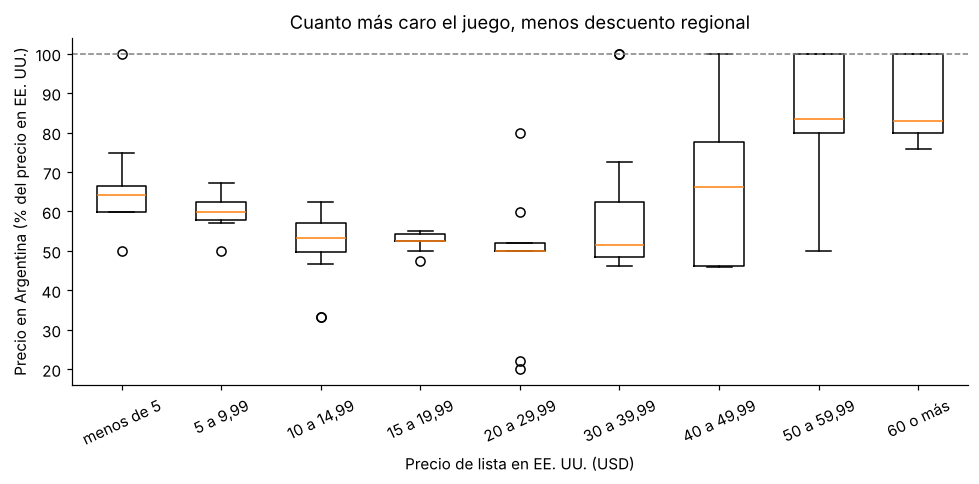

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
grupos = [precios.loc[precios["rango_us"] == n, "ar_sobre_us"] * 100 for n in nombres]
ax.boxplot(grupos)
ax.set_xticklabels(nombres)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("Precio en Argentina (% del precio en EE. UU.)")
ax.set_xlabel("Precio de lista en EE. UU. (USD)")
ax.set_title("Cuanto más caro el juego, menos descuento regional")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("../images/ar_vs_us_por_rango.png")
plt.show()

## 2. ¿Los juegos siguen la matriz de Valve?

In [4]:
matriz = pd.read_csv("../data/matrices_valve.csv")
m = precios.dropna(subset=["matriz2023_esperado"]).copy()
m["ratio_matriz"] = m["ar_inicial"] / m["matriz2023_esperado"]
m["sigue_matriz"] = (m["ratio_matriz"].round(3) == 1)
m["rango_us"] = pd.cut(m["us_inicial_usd"], cortes, labels=nombres, right=False)

print("Siguen la matriz exacta:", int(m["sigue_matriz"].sum()), "de", len(m))
print("Con base de 50 USD o más:", int(m.loc[m["us_inicial_usd"] >= 50, "sigue_matriz"].sum()),
      "de", int((m["us_inicial_usd"] >= 50).sum()))
m.groupby("rango_us", observed=True)["sigue_matriz"].agg(["sum", "count"]).rename(columns={"sum": "siguen", "count": "juegos"})

Siguen la matriz exacta: 29 de 101
Con base de 50 USD o más: 0 de 26


,siguen,juegos
rango_us,,
menos de 5,5,9
"5 a 9,99",3,11
"10 a 14,99",2,11
"15 a 19,99",5,10
"20 a 29,99",6,12
"30 a 39,99",4,12
"40 a 49,99",4,10
"50 a 59,99",0,16
60 o más,0,10


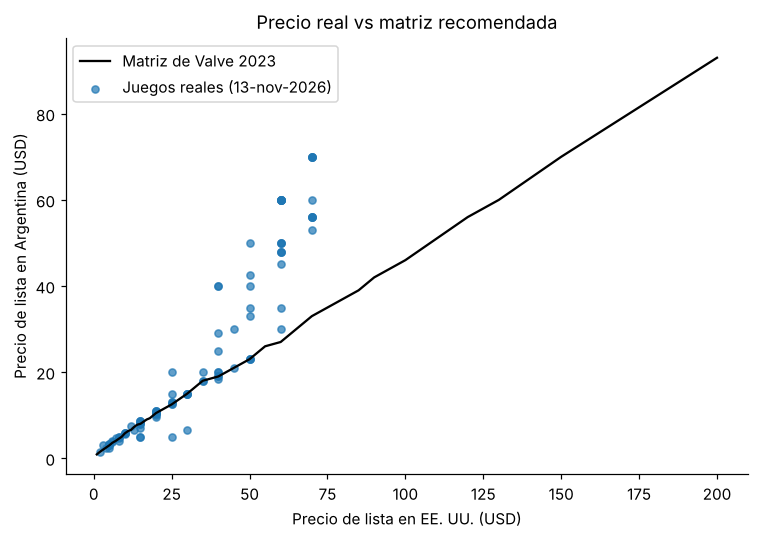

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(matriz["usd_tier"], matriz["latam_usd_matrix_2023"], color="black", label="Matriz de Valve 2023")
ax.scatter(m["us_inicial_usd"], m["ar_inicial"], s=22, alpha=0.7, label="Juegos reales (13-nov-2026)")
ax.set_xlabel("Precio de lista en EE. UU. (USD)")
ax.set_ylabel("Precio de lista en Argentina (USD)")
ax.set_title("Precio real vs matriz recomendada")
ax.legend()
plt.tight_layout()
plt.savefig("../images/ar_vs_matriz.png")
plt.show()

## 3. ¿Cuánto costó, con impuestos, un juego que sigue la matriz? (tier 59.99)

In [6]:
per = pd.read_csv("../data/dolar_efectivo_por_periodo.csv")
precio_matriz = 26.99  # matriz LATAM-USD 2023 para un juego de 59,99 USD
per["usd_a_oficial"] = precio_matriz * per["factor"]
per[["periodo_fecha", "carga_impositiva", "oficial_ars", "factor", "dolar_efectivo_ars", "usd_a_oficial"]].round(2)

,periodo_fecha,carga_impositiva,oficial_ars,factor,dolar_efectivo_ars,usd_a_oficial
0,2023-11-20,100% (PAIS30+Gan45+BP25),372.0,2.00,744.00,53.98
1,2023-11-23,155% (PAIS30+Gan100+BP25),372.0,2.55,948.60,68.82
2,2023-12-13,60% (PAIS30+Gan30),820.0,1.60,1312.00,43.18
3,2024-12-23,30% (percepcion; PAIS terminado),1044.0,1.30,1357.20,35.09
4,2026-03-27,IVA 21% (post RG 5677),1405.0,1.21,1700.05,32.66
5,2026-10-08,IVA 21% (post RG 5677),1539.3,1.21,1862.55,32.66


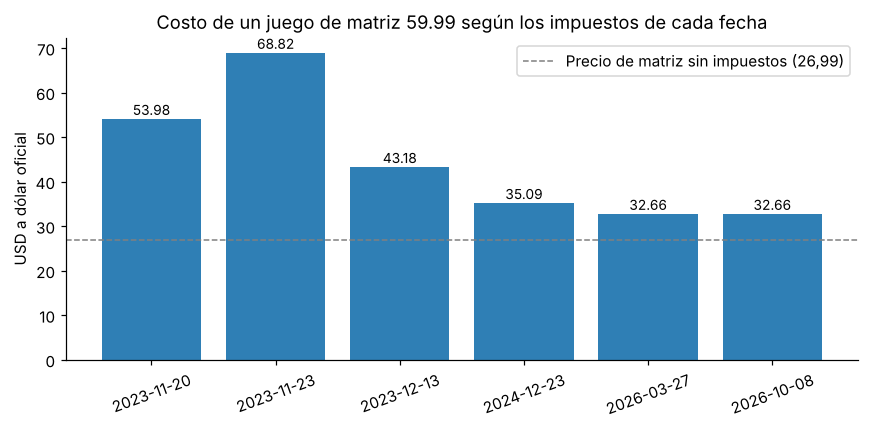

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(per["periodo_fecha"], per["usd_a_oficial"], color="#2f7fb5")
ax.axhline(precio_matriz, color="gray", linestyle="--", linewidth=1, label="Precio de matriz sin impuestos (26,99)")
for i, v in enumerate(per["usd_a_oficial"]):
    ax.text(i, v + 1, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylabel("USD a dólar oficial")
ax.set_title("Costo de un juego de matriz 59.99 según los impuestos de cada fecha")
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../images/costo_por_periodo.png")
plt.show()

## 4. Mis compras reales (2022 y 2026)

In [8]:
compras = pd.read_csv("../data/compras_propias.csv")
compras[["fecha_hora", "comercio_descriptor", "producto", "precio_total_usd_steam", "usd_cobrado_a_tarjeta", "monto_ars", "estado"]]

,fecha_hora,comercio_descriptor,producto,precio_total_usd_steam,usd_cobrado_a_tarjeta,monto_ars,estado
0,2022-06-20 22:10,Steam (factura web),Fondos Cartera Steam,NaN,NaN,400.00,Completada
1,2026-03-24 15:26,STEAMGAMES.COM 4259522,Elden Ring (intento),31.19,20.02,36099.58,Rechazada (saldo insuficiente)
2,2026-03-24 15:28,WL *STEAM PURCHASE,Elden Ring,31.19,20.02,28673.04,Completada
3,2026-05-28 03:41,WL *STEAM PURCHASE,Valheim,13.19,3.30,5160.39,Completada
4,2026-06-11 04:17,WL *STEAM PURCHASE,Carga Cartera Steam,10.00,10.00,NaN,"Completada (cobro 10,35 USD en cuenta AstroPay..."
